# 24C — GeoMAE-Inspired Final Model Robustness
## Multi-seed validation of Temporal Fire vs Spatiotemporal Fire

### Why this notebook exists

NB24B suggested:

- `T_FIRE` (temporal-only center-cell fire context) separates Emerging-3 from Persistent;
- `ST_FIRE` (7-day × 3×3 spatiotemporal fire context) showed a larger Emerging–Persistent separation;
- adding weather did not improve that separation.

However, one training run is not enough to claim that spatial context is consistently useful.

This notebook therefore performs a **multi-seed robustness comparison** between:

1. `T_FIRE`
2. `ST_FIRE`

under the same architecture, epochs, optimizer, mask ratio, and chronological split.

### Main question

> Is the stronger Emerging–Persistent separation of `ST_FIRE` reproducible across random seeds?

### Important

This is still representation validation, not ignition-cause classification.

September is not used for tuning here.

In [2]:
# 1. Imports

from pathlib import Path
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 320)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("DEVICE:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE: cpu


In [3]:
# 2. Resolve project root

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    checkpoint_path = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    nb23c_path = (
        root
        / "model_results"
        / "environmental_context_refinement"
        / "t2"
        / "exports"
        / "august_positive_refined_anomaly.csv"
    )

    if (
        data_path.exists()
        and checkpoint_path.exists()
        and nb23c_path.exists()
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate required project files. "
        "Run NB24 and NB23C first."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
    / "models"
    / "geomae_inspired_encoder.pt"
)

NB23C_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_context_refinement"
    / "t2"
    / "exports"
    / "august_positive_refined_anomaly.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_final_robustness"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
MODEL_DIR = RESULT_DIR / "models"

for p in [EXPORT_DIR, FIGURE_DIR, MODEL_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR:", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_final_robustness\t2


In [4]:
# 3. Load NB24 normalization / patch settings

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

TOKEN_FEATURES = list(
    checkpoint["token_features"]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v in checkpoint[
        "feature_mean"
    ].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v in checkpoint[
        "feature_std"
    ].items()
}

TEMPORAL_DAYS = int(
    checkpoint["temporal_days"]
)

SPATIAL_OFFSETS = [
    tuple(x)
    for x in checkpoint[
        "spatial_offsets"
    ]
]

CENTER_TOKEN_INDEX = int(
    checkpoint["center_token_index"]
)

MASK_RATIO = float(
    checkpoint["mask_ratio"]
)

PRETRAIN_END = pd.Timestamp(
    checkpoint["pretrain_end"]
)

DEV_START = pd.Timestamp("2026-08-01")
DEV_END = pd.Timestamp("2026-08-31")

GRID_STEP = 0.25
N_SPATIAL = len(SPATIAL_OFFSETS)
N_TOKENS = TEMPORAL_DAYS * N_SPATIAL

FIRE_FEATURES = [
    "fire_active",
    "fire_count_log1p",
    "frp_sum_log1p",
]

FIRE_FEATURE_INDICES = [
    TOKEN_FEATURES.index(c)
    for c in FIRE_FEATURES
]

print("Token features:", TOKEN_FEATURES)
print("Pretraining ends:", PRETRAIN_END.date())

Token features: ['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']
Pretraining ends: 2026-07-31


In [5]:
# 4. Load regional data and recreate NB24 normalization

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(
        ["date", "cell_id"]
    )
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

for feature in TOKEN_FEATURES:
    df[f"z__{feature}"] = (
        (
            df[feature]
            - FEATURE_MEAN[feature]
        )
        / FEATURE_STD[feature]
    )

Z_FEATURES = [
    f"z__{c}"
    for c in TOKEN_FEATURES
]

df["token_valid"] = (
    df[Z_FEATURES]
    .notna()
    .all(axis=1)
)

print("Rows:", len(df))
print("Nodes:", df["cell_id"].nunique())

Rows: 16625
Nodes: 133


In [6]:
# 5. Build lookup and patch arrays

work = df.copy()

work["lat_key"] = work[
    "grid_lat"
].round(3)

work["lon_key"] = work[
    "grid_lon"
].round(3)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row in work[
        [
            "date",
            "lat_key",
            "lon_key",
        ]
    ].iterrows()
}

z_matrix = (
    work[Z_FEATURES]
    .to_numpy(
        dtype=np.float32
    )
)

valid_vector = (
    work["token_valid"]
    .to_numpy(
        dtype=bool
    )
)

CENTER_SPATIAL_INDEX = (
    SPATIAL_OFFSETS.index(
        (0, 0)
    )
)


def build_patch(
    center_date,
    center_lat,
    center_lon,
):
    x = np.zeros(
        (
            N_TOKENS,
            len(Z_FEATURES),
        ),
        dtype=np.float32,
    )

    valid = np.zeros(
        N_TOKENS,
        dtype=bool,
    )

    token_idx = 0
    center_date = pd.Timestamp(
        center_date
    )

    for day_back in range(
        TEMPORAL_DAYS - 1,
        -1,
        -1,
    ):
        token_date = (
            center_date
            - pd.Timedelta(
                days=day_back
            )
        )

        for dx, dy in SPATIAL_OFFSETS:
            lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    token_date,
                    lat,
                    lon,
                )
            )

            if (
                idx is not None
                and valid_vector[idx]
            ):
                x[token_idx] = (
                    z_matrix[idx]
                )
                valid[token_idx] = True

            token_idx += 1

    return x, valid

In [7]:
# 6. Materialize sample tensor

min_date = (
    pd.Timestamp(
        work["date"].min()
    )
    + pd.Timedelta(
        days=TEMPORAL_DAYS - 1
    )
)

sample_meta = (
    work[
        work["date"] >= min_date
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "fire_active",
            "fire_count",
            "frp_sum",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

patches = []
valid_masks = []
kept_meta = []

for row in sample_meta.itertuples(
    index=False
):
    x, valid = build_patch(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    if not valid[
        CENTER_TOKEN_INDEX
    ]:
        continue

    patches.append(x)
    valid_masks.append(valid)
    kept_meta.append(
        row._asdict()
    )

X = np.stack(
    patches
).astype(np.float32)

VALID = np.stack(
    valid_masks
).astype(bool)

META = pd.DataFrame(
    kept_meta
)

train_idx = np.flatnonzero(
    META["date"]
    .le(PRETRAIN_END)
    .to_numpy()
)

aug_idx = np.flatnonzero(
    META["date"]
    .between(
        DEV_START,
        DEV_END,
    )
    .to_numpy()
)

print("Patch tensor:", X.shape)
print("Train samples:", len(train_idx))
print("August samples:", len(aug_idx))

Patch tensor: (15827, 63, 13)
Train samples: 10507
August samples: 4123


In [8]:
# 7. Load Emerging / Persistent evaluation labels

nb23c_pos = pd.read_csv(
    NB23C_PATH,
    parse_dates=[
        "date",
        "event_date",
    ],
)

print(
    nb23c_pos[
        "research_group"
    ].value_counts()
)

research_group
Persistent    1849
Emerging-3     217
Name: count, dtype: int64


# PART A — Locked robustness design

We now freeze the comparison before seeing the multi-seed result.

### Models

- `T_FIRE`: 7 temporal tokens from the center cell, fire channels only.
- `ST_FIRE`: 63 tokens from 7 days × 3×3 neighborhood, fire channels only.

### Fixed settings

- 5 random seeds
- 10 epochs per run
- same hidden dimension
- same number of heads/layers
- same optimizer
- same mask ratio
- same May–July pretraining period
- same August evaluation
- no weather

### Primary robustness metric

For every seed and model:

> median day-ranked reconstruction anomaly of Emerging-3 minus Persistent.

Higher positive values indicate that Emerging-3 events are harder to reconstruct than Persistent events.

We do not choose the seed with the best result.
All seeds are reported.

In [9]:
# 8. Locked multi-seed configuration

SEEDS = [
    11,
    22,
    33,
    44,
    55,
]

EPOCHS = 10
BATCH_SIZE = 128

D_MODEL = 48
NHEAD = 4
NUM_LAYERS = 2
DIM_FEEDFORWARD = 96

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

print("Seeds:", SEEDS)
print("Epochs per run:", EPOCHS)
print("Total model fits:", len(SEEDS) * 2)

Seeds: [11, 22, 33, 44, 55]
Epochs per run: 10
Total model fits: 10


In [10]:
# 9. Prepare T_FIRE and ST_FIRE tensors

center_temporal_token_indices = [
    (
        t * N_SPATIAL
        + CENTER_SPATIAL_INDEX
    )
    for t in range(
        TEMPORAL_DAYS
    )
]

full_token_time = []
full_token_space = []

for t in range(
    TEMPORAL_DAYS
):
    for s in range(
        N_SPATIAL
    ):
        full_token_time.append(t)
        full_token_space.append(s)

VARIANTS = {
    "T_FIRE": {
        "X": X[
            :,
            center_temporal_token_indices,
            :
        ][
            :,
            :,
            FIRE_FEATURE_INDICES,
        ],
        "VALID": VALID[
            :,
            center_temporal_token_indices,
        ],
        "token_time": list(
            range(TEMPORAL_DAYS)
        ),
        "token_space": [
            0
            for _ in range(
                TEMPORAL_DAYS
            )
        ],
        "n_time": TEMPORAL_DAYS,
        "n_space": 1,
        "center_index": TEMPORAL_DAYS - 1,
        "fire_indices": [
            0,
            1,
            2,
        ],
    },
    "ST_FIRE": {
        "X": X[
            :,
            :,
            FIRE_FEATURE_INDICES,
        ],
        "VALID": VALID,
        "token_time": full_token_time,
        "token_space": full_token_space,
        "n_time": TEMPORAL_DAYS,
        "n_space": N_SPATIAL,
        "center_index": CENTER_TOKEN_INDEX,
        "fire_indices": [
            0,
            1,
            2,
        ],
    },
}

for name, cfg in VARIANTS.items():
    print(name, cfg["X"].shape)

T_FIRE (15827, 7, 3)
ST_FIRE (15827, 63, 3)


In [11]:
# 10. Generic dataset

class ArrayDataset(Dataset):
    def __init__(
        self,
        X_array,
        valid_array,
        indices,
    ):
        self.X = X_array
        self.valid = valid_array
        self.indices = np.asarray(
            indices
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        return (
            torch.from_numpy(
                self.X[idx]
            ),
            torch.from_numpy(
                self.valid[idx]
            ),
            idx,
        )

In [12]:
# 11. Small masked Transformer

class SmallMaskedTransformer(nn.Module):
    def __init__(
        self,
        n_features,
        token_time,
        token_space,
        n_time,
        n_space,
    ):
        super().__init__()

        self.input_proj = nn.Linear(
            n_features,
            D_MODEL,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                D_MODEL,
            )
        )

        self.time_embedding = nn.Embedding(
            n_time,
            D_MODEL,
        )

        self.space_embedding = nn.Embedding(
            n_space,
            D_MODEL,
        )

        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=DIM_FEEDFORWARD,
            dropout=0.10,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.encoder = nn.TransformerEncoder(
            layer,
            num_layers=NUM_LAYERS,
        )

        self.norm = nn.LayerNorm(
            D_MODEL
        )

        self.reconstruction_head = nn.Linear(
            D_MODEL,
            n_features,
        )

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

        nn.init.normal_(
            self.mask_token,
            std=0.02,
        )

    def forward(
        self,
        x,
        valid_mask,
        mask_positions,
    ):
        h = self.input_proj(x)

        mask_embed = (
            self.mask_token.expand(
                x.shape[0],
                x.shape[1],
                -1,
            )
        )

        h = torch.where(
            mask_positions.unsqueeze(-1),
            mask_embed,
            h,
        )

        h = (
            h
            + self.time_embedding(
                self.token_time
            ).unsqueeze(0)
            + self.space_embedding(
                self.token_space
            ).unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        h = self.norm(h)

        return self.reconstruction_head(h)

In [13]:
# 12. Reproducibility helper

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def random_mask_positions(
    valid_mask,
    ratio,
):
    values = torch.rand(
        valid_mask.shape,
        device=valid_mask.device,
    )

    mask = (
        values < ratio
    ) & valid_mask

    for i in range(
        mask.shape[0]
    ):
        if not mask[i].any():
            valid_idx = torch.where(
                valid_mask[i]
            )[0]

            chosen = valid_idx[
                torch.randint(
                    0,
                    len(valid_idx),
                    (1,),
                    device=valid_mask.device,
                )
            ]

            mask[
                i,
                chosen,
            ] = True

    return mask

In [14]:
# 13. Train one seed / one variant

def train_one(
    variant_name,
    cfg,
    seed,
):
    set_seed(seed)

    model = SmallMaskedTransformer(
        n_features=cfg[
            "X"
        ].shape[-1],
        token_time=cfg[
            "token_time"
        ],
        token_space=cfg[
            "token_space"
        ],
        n_time=cfg[
            "n_time"
        ],
        n_space=cfg[
            "n_space"
        ],
    ).to(DEVICE)

    dataset = ArrayDataset(
        cfg["X"],
        cfg["VALID"],
        train_idx,
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    best_loss = np.inf
    best_state = None
    history = []

    for epoch in range(
        1,
        EPOCHS + 1,
    ):
        model.train()

        losses = []

        for (
            x_batch,
            valid_batch,
            _
        ) in loader:
            x_batch = x_batch.to(
                DEVICE
            )

            valid_batch = valid_batch.to(
                DEVICE
            )

            mask = random_mask_positions(
                valid_batch,
                MASK_RATIO,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            pred = model(
                x_batch,
                valid_batch,
                mask,
            )

            loss = (
                (
                    pred
                    - x_batch
                ) ** 2
            )[mask].mean()

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0,
            )

            optimizer.step()

            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

        epoch_loss = float(
            np.mean(losses)
        )

        history.append({
            "variant": variant_name,
            "seed": seed,
            "epoch": epoch,
            "masked_mse": epoch_loss,
        })

        if epoch_loss < best_loss:
            best_loss = epoch_loss

            best_state = {
                k: v.detach()
                .cpu()
                .clone()
                for k, v
                in model.state_dict().items()
            }

        print(
            f"{variant_name} | seed={seed} | "
            f"epoch={epoch:02d}/{EPOCHS} | "
            f"MSE={epoch_loss:.4f}"
        )

    model.load_state_dict(
        best_state
    )

    return (
        model,
        pd.DataFrame(history),
        best_loss,
    )

In [15]:
# 14. Score August center reconstruction

@torch.no_grad()
def score_august(
    model,
    cfg,
):
    dataset = ArrayDataset(
        cfg["X"],
        cfg["VALID"],
        aug_idx,
    )

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for (
        x_batch,
        valid_batch,
        idx_batch,
    ) in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        center_mask = torch.zeros_like(
            valid_batch
        )

        center_mask[
            :,
            cfg[
                "center_index"
            ],
        ] = True

        center_mask = (
            center_mask
            & valid_batch
        )

        pred = model(
            x_batch,
            valid_batch,
            center_mask,
        )

        true_center = x_batch[
            :,
            cfg[
                "center_index"
            ],
            :
        ]

        pred_center = pred[
            :,
            cfg[
                "center_index"
            ],
            :
        ]

        fire_error = (
            (
                pred_center[
                    :,
                    cfg[
                        "fire_indices"
                    ],
                ]
                - true_center[
                    :,
                    cfg[
                        "fire_indices"
                    ],
                ]
            ) ** 2
        ).mean(
            dim=1
        )

        for idx, value in zip(
            idx_batch.numpy(),
            fire_error.detach()
            .cpu()
            .numpy(),
        ):
            rows.append({
                "sample_index": int(idx),
                "fire_reconstruction_error": float(value),
            })

    scores = pd.DataFrame(
        rows
    )

    scores = (
        META.iloc[
            scores[
                "sample_index"
            ].to_numpy()
        ]
        .reset_index()
        .rename(
            columns={
                "index": "sample_index"
            }
        )
        .merge(
            scores,
            on="sample_index",
            how="left",
            validate="one_to_one",
        )
    )

    scores[
        "fire_reconstruction_rank"
    ] = (
        scores
        .groupby(
            "date"
        )[
            "fire_reconstruction_error"
        ]
        .rank(
            pct=True,
            ascending=True,
            method="average",
        )
    )

    return scores

In [16]:
# 15. Evaluation helper

def evaluate_emerging_persistent(
    scores,
):
    positive = (
        scores[
            scores[
                "fire_active"
            ].eq(1)
        ]
        .copy()
        .rename(
            columns={
                "date": "event_date"
            }
        )
    )

    merged = (
        nb23c_pos[
            [
                "event_date",
                "cell_id",
                "research_group",
            ]
        ]
        .merge(
            positive[
                [
                    "event_date",
                    "cell_id",
                    "fire_reconstruction_rank",
                ]
            ],
            on=[
                "event_date",
                "cell_id",
            ],
            how="inner",
        )
    )

    emerging = (
        merged.loc[
            merged[
                "research_group"
            ].eq(
                "Emerging-3"
            ),
            "fire_reconstruction_rank",
        ]
        .dropna()
    )

    persistent = (
        merged.loc[
            merged[
                "research_group"
            ].eq(
                "Persistent"
            ),
            "fire_reconstruction_rank",
        ]
        .dropna()
    )

    result = {
        "emerging_n": len(emerging),
        "persistent_n": len(persistent),
        "emerging_mean": float(
            emerging.mean()
        ),
        "persistent_mean": float(
            persistent.mean()
        ),
        "emerging_median": float(
            emerging.median()
        ),
        "persistent_median": float(
            persistent.median()
        ),
        "median_difference": float(
            emerging.median()
            - persistent.median()
        ),
    }

    return result

# PART B — Run all seeds

This may take several minutes because 10 models are trained.

Do not stop because one seed is weaker than another.
All seeds are part of the robustness result.

In [17]:
# 16. Multi-seed experiment

all_results = []
all_history = []

for variant_name, cfg in VARIANTS.items():
    for seed in SEEDS:
        print()
        print("=" * 78)
        print(
            variant_name,
            "| seed",
            seed,
        )
        print("=" * 78)

        model, history, best_loss = (
            train_one(
                variant_name,
                cfg,
                seed,
            )
        )

        scores = score_august(
            model,
            cfg,
        )

        metrics = (
            evaluate_emerging_persistent(
                scores
            )
        )

        metrics.update({
            "variant": variant_name,
            "seed": seed,
            "best_training_mse": float(
                best_loss
            ),
        })

        all_results.append(
            metrics
        )

        all_history.append(
            history
        )

        model_path = (
            MODEL_DIR
            / f"{variant_name}_seed{seed}.pt"
        )

        torch.save(
            {
                "variant": variant_name,
                "seed": seed,
                "model_state_dict": model.state_dict(),
                "settings": {
                    "epochs": EPOCHS,
                    "d_model": D_MODEL,
                    "nhead": NHEAD,
                    "num_layers": NUM_LAYERS,
                    "mask_ratio": MASK_RATIO,
                },
            },
            model_path,
        )

results = pd.DataFrame(
    all_results
)

history_df = pd.concat(
    all_history,
    ignore_index=True,
)

display(
    results.sort_values(
        [
            "variant",
            "seed",
        ]
    )
)


T_FIRE | seed 11
T_FIRE | seed=11 | epoch=01/10 | MSE=0.7505
T_FIRE | seed=11 | epoch=02/10 | MSE=0.7033
T_FIRE | seed=11 | epoch=03/10 | MSE=0.6984
T_FIRE | seed=11 | epoch=04/10 | MSE=0.6761
T_FIRE | seed=11 | epoch=05/10 | MSE=0.6538
T_FIRE | seed=11 | epoch=06/10 | MSE=0.6889
T_FIRE | seed=11 | epoch=07/10 | MSE=0.6847
T_FIRE | seed=11 | epoch=08/10 | MSE=0.6898
T_FIRE | seed=11 | epoch=09/10 | MSE=0.6384
T_FIRE | seed=11 | epoch=10/10 | MSE=0.6377

T_FIRE | seed 22
T_FIRE | seed=22 | epoch=01/10 | MSE=0.8197
T_FIRE | seed=22 | epoch=02/10 | MSE=0.6890
T_FIRE | seed=22 | epoch=03/10 | MSE=0.6824
T_FIRE | seed=22 | epoch=04/10 | MSE=0.6702
T_FIRE | seed=22 | epoch=05/10 | MSE=0.6525
T_FIRE | seed=22 | epoch=06/10 | MSE=0.6651
T_FIRE | seed=22 | epoch=07/10 | MSE=0.6524
T_FIRE | seed=22 | epoch=08/10 | MSE=0.6613
T_FIRE | seed=22 | epoch=09/10 | MSE=0.6621
T_FIRE | seed=22 | epoch=10/10 | MSE=0.6684

T_FIRE | seed 33
T_FIRE | seed=33 | epoch=01/10 | MSE=0.7707
T_FIRE | seed=33 | epo

,emerging_n,persistent_n,emerging_mean,persistent_mean,emerging_median,persistent_median,median_difference,variant,seed,best_training_mse
5,217,1849,0.758844,0.584303,0.781955,0.609023,0.172932,ST_FIRE,11,0.662380
6,217,1849,0.778109,0.605172,0.819549,0.624060,0.195489,ST_FIRE,22,0.657766
7,217,1849,0.797027,0.594965,0.819549,0.616541,0.203008,ST_FIRE,33,0.656698
8,217,1849,0.752399,0.608282,0.781955,0.631579,0.150376,ST_FIRE,44,0.661267
9,217,1849,0.797685,0.625601,0.812030,0.654135,0.157895,ST_FIRE,55,0.664323
0,217,1849,0.817123,0.634446,0.827068,0.654135,0.172932,T_FIRE,11,0.637680
1,217,1849,0.818683,0.607469,0.827068,0.609023,0.218045,T_FIRE,22,0.652428
2,217,1849,0.806763,0.639594,0.812030,0.654135,0.157895,T_FIRE,33,0.638607
3,217,1849,0.825786,0.626829,0.834586,0.639098,0.195489,T_FIRE,44,0.632103
4,217,1849,0.801670,0.644677,0.812030,0.661654,0.150376,T_FIRE,55,0.630941


In [18]:
# 17. Robustness summary across seeds

summary = (
    results
    .groupby(
        "variant"
    )
    .agg(
        seeds=(
            "seed",
            "nunique",
        ),
        median_difference_mean=(
            "median_difference",
            "mean",
        ),
        median_difference_median=(
            "median_difference",
            "median",
        ),
        median_difference_std=(
            "median_difference",
            "std",
        ),
        median_difference_min=(
            "median_difference",
            "min",
        ),
        median_difference_max=(
            "median_difference",
            "max",
        ),
        emerging_rank_mean_across_seeds=(
            "emerging_mean",
            "mean",
        ),
        persistent_rank_mean_across_seeds=(
            "persistent_mean",
            "mean",
        ),
        training_mse_mean=(
            "best_training_mse",
            "mean",
        ),
    )
    .reset_index()
)

display(summary)

,variant,seeds,median_difference_mean,median_difference_median,median_difference_std,median_difference_min,median_difference_max,emerging_rank_mean_across_seeds,persistent_rank_mean_across_seeds,training_mse_mean
0,ST_FIRE,5,0.175940,0.172932,0.022929,0.150376,0.203008,0.776813,0.603665,0.660487
1,T_FIRE,5,0.178947,0.172932,0.027830,0.150376,0.218045,0.814005,0.630603,0.638352


In [19]:
# 18. Paired seed-by-seed ST_FIRE minus T_FIRE

paired = (
    results[
        [
            "variant",
            "seed",
            "median_difference",
        ]
    ]
    .pivot(
        index="seed",
        columns="variant",
        values="median_difference",
    )
    .reset_index()
)

paired[
    "ST_minus_T"
] = (
    paired[
        "ST_FIRE"
    ]
    - paired[
        "T_FIRE"
    ]
)

display(paired)

print()
print(
    "Mean ST_FIRE - T_FIRE difference:",
    round(
        float(
            paired[
                "ST_minus_T"
            ].mean()
        ),
        6,
    ),
)

print(
    "Median ST_FIRE - T_FIRE difference:",
    round(
        float(
            paired[
                "ST_minus_T"
            ].median()
        ),
        6,
    ),
)

print(
    "Seeds where ST_FIRE > T_FIRE:",
    int(
        (
            paired[
                "ST_minus_T"
            ] > 0
        ).sum()
    ),
    "/",
    len(paired),
)

variant,seed,ST_FIRE,T_FIRE,ST_minus_T
0,11,0.172932,0.172932,0.000000
1,22,0.195489,0.218045,-0.022556
2,33,0.203008,0.157895,0.045113
3,44,0.150376,0.195489,-0.045113
4,55,0.157895,0.150376,0.007519



Mean ST_FIRE - T_FIRE difference: -0.003008
Median ST_FIRE - T_FIRE difference: 0.0
Seeds where ST_FIRE > T_FIRE: 2 / 5


In [20]:
# 19. Seed-bootstrap CI for paired ST_FIRE - T_FIRE difference

rng = np.random.default_rng(
    2026
)

paired_values = (
    paired[
        "ST_minus_T"
    ]
    .dropna()
    .to_numpy()
)

N_BOOT = 5000

boot_means = []

for _ in range(
    N_BOOT
):
    sample = rng.choice(
        paired_values,
        size=len(paired_values),
        replace=True,
    )

    boot_means.append(
        float(
            np.mean(sample)
        )
    )

paired_bootstrap = pd.DataFrame({
    "metric": [
        "mean_ST_FIRE_minus_T_FIRE"
    ],
    "observed": [
        float(
            paired_values.mean()
        )
    ],
    "bootstrap_2.5%": [
        float(
            np.quantile(
                boot_means,
                0.025,
            )
        )
    ],
    "bootstrap_97.5%": [
        float(
            np.quantile(
                boot_means,
                0.975,
            )
        )
    ],
    "bootstrap_samples": [
        N_BOOT
    ],
})

display(
    paired_bootstrap
)

,metric,observed,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,mean_ST_FIRE_minus_T_FIRE,-0.003008,-0.027068,0.02406,5000


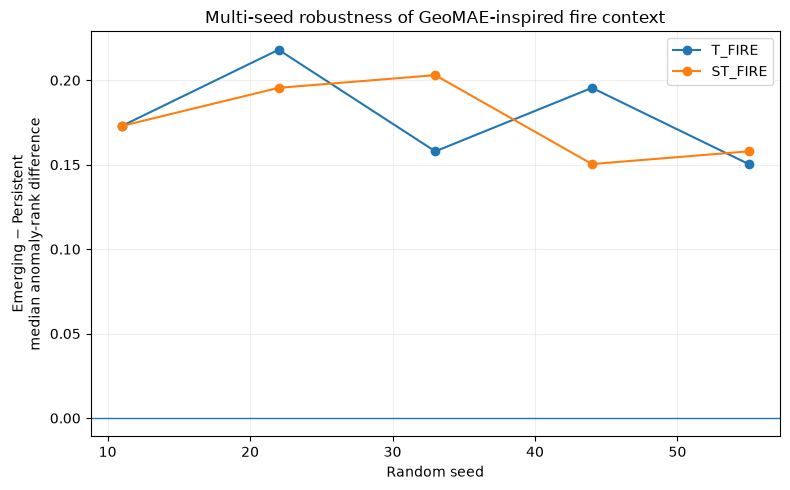

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_final_robustness\t2\figures\01_multiseed_T_vs_ST.png


In [21]:
# 20. Robustness plot

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for variant in [
    "T_FIRE",
    "ST_FIRE",
]:
    subset = (
        results[
            results[
                "variant"
            ].eq(variant)
        ]
        .sort_values(
            "seed"
        )
    )

    ax.plot(
        subset[
            "seed"
        ],
        subset[
            "median_difference"
        ],
        marker="o",
        label=variant,
    )

ax.axhline(
    0,
    linewidth=1,
)

ax.set_xlabel(
    "Random seed"
)

ax.set_ylabel(
    "Emerging − Persistent\nmedian anomaly-rank difference"
)

ax.set_title(
    "Multi-seed robustness of GeoMAE-inspired fire context"
)

ax.grid(
    alpha=0.2
)

ax.legend()

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "01_multiseed_T_vs_ST.png"
)

plt.savefig(
    plot_path,
    dpi=190,
    bbox_inches="tight",
)

plt.show()

print("Saved:", plot_path)

# PART C — Architecture freeze decision

Use the multi-seed evidence, not the single best run.

A reasonable interpretation is:

### Freeze `ST_FIRE` if:
- its Emerging–Persistent separation remains positive across all/most seeds;
- it is consistently or generally higher than `T_FIRE`;
- the paired difference is not dominated by one outlier seed.

### Freeze `T_FIRE` if:
- `ST_FIRE` does not show a stable advantage;
- spatial context adds complexity without reproducible benefit.

Do not reintroduce weather unless a new experiment has a clear reason.

In [22]:
# 21. Automatic architecture recommendation from robustness evidence

st = results[
    results[
        "variant"
    ].eq(
        "ST_FIRE"
    )
]

tt = results[
    results[
        "variant"
    ].eq(
        "T_FIRE"
    )
]

st_positive_share = float(
    (
        st[
            "median_difference"
        ] > 0
    ).mean()
)

t_positive_share = float(
    (
        tt[
            "median_difference"
        ] > 0
    ).mean()
)

st_beats_t_share = float(
    (
        paired[
            "ST_minus_T"
        ] > 0
    ).mean()
)

if (
    st_positive_share >= 0.80
    and st_beats_t_share >= 0.60
):
    FINAL_CANDIDATE = (
        "ST_FIRE"
    )
else:
    FINAL_CANDIDATE = (
        "T_FIRE"
    )

print(
    "ST_FIRE positive-separation seed share:",
    round(
        st_positive_share,
        3,
    ),
)

print(
    "T_FIRE positive-separation seed share:",
    round(
        t_positive_share,
        3,
    ),
)

print(
    "ST_FIRE beats T_FIRE seed share:",
    round(
        st_beats_t_share,
        3,
    ),
)

print()
print(
    "ROBUSTNESS-BASED FINAL CANDIDATE:",
    FINAL_CANDIDATE,
)

print()
print(
    "This is an architecture-freeze aid, not a claim of ignition-cause detection."
)

ST_FIRE positive-separation seed share: 1.0
T_FIRE positive-separation seed share: 1.0
ST_FIRE beats T_FIRE seed share: 0.4

ROBUSTNESS-BASED FINAL CANDIDATE: T_FIRE

This is an architecture-freeze aid, not a claim of ignition-cause detection.


In [23]:
# 22. Save outputs

RESULTS_PATH = (
    EXPORT_DIR
    / "multiseed_results.csv"
)

SUMMARY_PATH = (
    EXPORT_DIR
    / "multiseed_summary.csv"
)

PAIRED_PATH = (
    EXPORT_DIR
    / "paired_ST_vs_T.csv"
)

BOOT_PATH = (
    EXPORT_DIR
    / "paired_seed_bootstrap.csv"
)

HISTORY_PATH = (
    EXPORT_DIR
    / "training_history_all_seeds.csv"
)

META_PATH = (
    EXPORT_DIR
    / "nb24c_methodology_metadata.json"
)

results.to_csv(
    RESULTS_PATH,
    index=False,
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

paired.to_csv(
    PAIRED_PATH,
    index=False,
)

paired_bootstrap.to_csv(
    BOOT_PATH,
    index=False,
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

metadata = {
    "notebook": "24C_geomae_final_model_robustness",
    "variants": [
        "T_FIRE",
        "ST_FIRE",
    ],
    "seeds": SEEDS,
    "epochs": EPOCHS,
    "mask_ratio": MASK_RATIO,
    "pretraining_end": str(
        PRETRAIN_END.date()
    ),
    "development_period": "August 2026",
    "weather_used": False,
    "final_candidate": FINAL_CANDIDATE,
    "selection_basis": (
        "multi-seed robustness of Emerging-3 vs Persistent reconstruction-rank separation"
    ),
    "important_limit": (
        "The model identifies contextual hotspot anomalies, not ignition causes."
    ),
}

META_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_final_robustness\t2\exports


In [24]:
# 23. Final review block

print("=== NB24C FINAL REVIEW ===")
print()

display(summary)

print()
print("Paired ST_FIRE - T_FIRE by seed:")
display(paired)

print()
print("Paired seed-bootstrap:")
display(paired_bootstrap)

print()
print(
    "Final architecture candidate:",
    FINAL_CANDIDATE,
)

print()
print(
    "Do not tune this architecture on September after freezing it."
)

=== NB24C FINAL REVIEW ===



,variant,seeds,median_difference_mean,median_difference_median,median_difference_std,median_difference_min,median_difference_max,emerging_rank_mean_across_seeds,persistent_rank_mean_across_seeds,training_mse_mean
0,ST_FIRE,5,0.175940,0.172932,0.022929,0.150376,0.203008,0.776813,0.603665,0.660487
1,T_FIRE,5,0.178947,0.172932,0.027830,0.150376,0.218045,0.814005,0.630603,0.638352



Paired ST_FIRE - T_FIRE by seed:


variant,seed,ST_FIRE,T_FIRE,ST_minus_T
0,11,0.172932,0.172932,0.000000
1,22,0.195489,0.218045,-0.022556
2,33,0.203008,0.157895,0.045113
3,44,0.150376,0.195489,-0.045113
4,55,0.157895,0.150376,0.007519



Paired seed-bootstrap:


,metric,observed,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,mean_ST_FIRE_minus_T_FIRE,-0.003008,-0.027068,0.02406,5000



Final architecture candidate: T_FIRE

Do not tune this architecture on September after freezing it.


# What to send back

After **Run All**, send the executed NB24C notebook.

The key outputs are:

1. `multiseed_results`
2. `multiseed_summary`
3. paired `ST_FIRE - T_FIRE` table
4. paired seed-bootstrap interval
5. `FINAL_CANDIDATE`

After this notebook, the next step is **not another architecture search**.

If the result is robust, we freeze the final model and move to:

- final anomaly scoring;
- candidate stability;
- case-study visualization;
- thesis methodology/result write-up;
- and only then a secondary chronological evaluation.